#imports

In [ ]:
import pandas as pd; import numpy as np ; import matplotlib.pyplot as plt ; import seaborn as sns;
from numpy import argmax;
import scipy.stats as st;

from sklearn.datasets import make_classification as mc;
from sklearn.datasets import make_regression as mr
from sklearn.datasets import load_iris;
from sklearn.datasets import load_diabetes

from sklearn.metrics import precision_recall_curve as prc;
from sklearn.metrics import roc_curve as roc;
from sklearn.metrics import classification_report as report;
from sklearn.metrics import roc_auc_score;
from sklearn.metrics import precision_score;
from sklearn.metrics import recall_score;
from sklearn.metrics import get_scorer_names
from sklearn.metrics import f1_score as f1
from sklearn.metrics import accuracy_score as accuracy
from sklearn.metrics import r2_score

from sklearn.linear_model import LogisticRegression as LR;
from sklearn.linear_model import LinearRegression as LinReg;
from sklearn.linear_model import Lasso
from sklearn.linear_model import ElasticNet
from sklearn.linear_model import SGDClassifier as SGDC;

from sklearn.model_selection import train_test_split;
from sklearn.model_selection import cross_validate;
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import KFold;
from sklearn.model_selection import LearningCurveDisplay
from sklearn.model_selection import RandomizedSearchCV as RSCV;
from sklearn.model_selection import LeavePOut;
from sklearn.model_selection import GridSearchCV as GSCV;

from sklearn.neighbors import KNeighborsRegressor as KNNR
from sklearn.neighbors import KNeighborsClassifier as KNNC

from sklearn.gaussian_process import GaussianProcessClassifier as GPC
from sklearn.gaussian_process.kernels import RBF

from sklearn.preprocessing import OneHotEncoder as OHE;
from sklearn.preprocessing import StandardScaler as SC;

from sklearn.ensemble import RandomForestClassifier as RFC;
from sklearn.ensemble import RandomForestRegressor as RFR;
from sklearn.ensemble import GradientBoostingClassifier as GBC
from sklearn.ensemble import ExtraTreesClassifier as ETC;
from sklearn.ensemble import ExtraTreesRegressor as ETR;
from sklearn.ensemble import AdaBoostClassifier as AdaBoost;
from sklearn.ensemble import AdaBoostRegressor;
from sklearn.ensemble import GradientBoostingRegressor as GBR;

from sklearn.tree import DecisionTreeClassifier as DTC;
from sklearn.tree import DecisionTreeRegressor  as DTR

from sklearn.naive_bayes import GaussianNB as GNB;

from sklearn.svm import SVC;
from sklearn.svm import SVR;

from sklearn.neural_network import MLPClassifier as MLPC
from sklearn.neural_network import MLPRegressor as MLPR;

from yellowbrick.classifier import ROCAUC;
from yellowbrick.classifier import PrecisionRecallCurve;

from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis as QDA;

from yellowbrick.model_selection import LearningCurve

from sklearn.pipeline import make_pipeline;

from tqdm.notebook import tqdm

import warnings;warnings.simplefilter("ignore")

# 1. При выполнении 3 и 5 заданий используйте другие методы визуализации. Найдите самый подходящий тип графика для каждого распределения.

3 Постройте визуализацию распределения каждого численного атрибута.

5 Постройте совместное распределение каждого признака вместе с целевой переменной. Сделайте вывод о необходимости проведения группировки данных.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35064 entries, 0 to 35063
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  35064 non-null  int64  
 1   No          35064 non-null  int64  
 2   SO2         35064 non-null  float64
 3   NO2         35064 non-null  float64
 4   CO          35064 non-null  float64
 5   O3          35064 non-null  float64
 6   PRES        35064 non-null  float64
 7   RAIN        35064 non-null  float64
 8   wd          35064 non-null  object 
 9   WSPM        35064 non-null  float64
 10  AQI Label   35064 non-null  object 
dtypes: float64(7), int64(2), object(2)
memory usage: 2.9+ MB


None

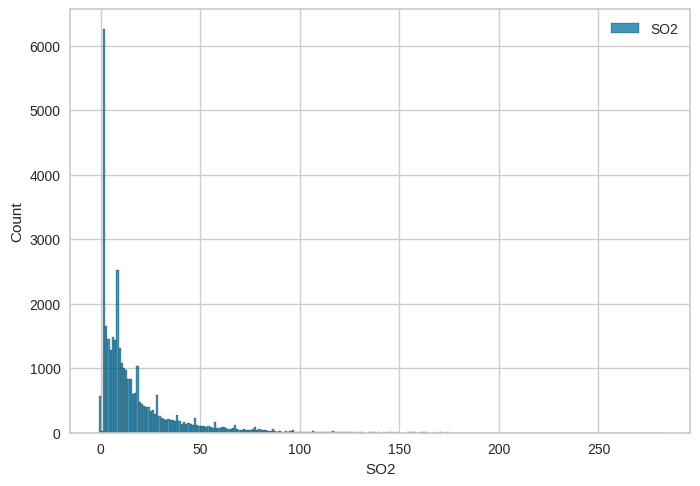

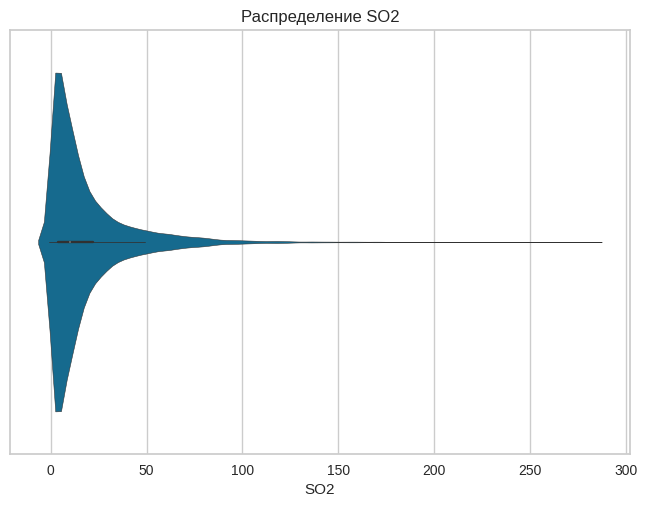

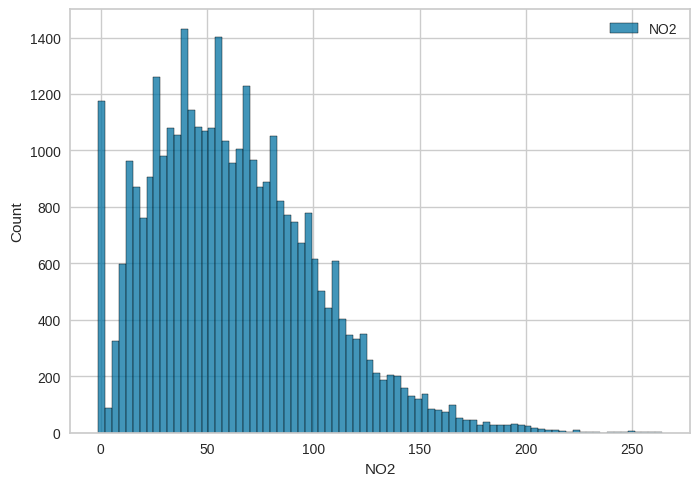

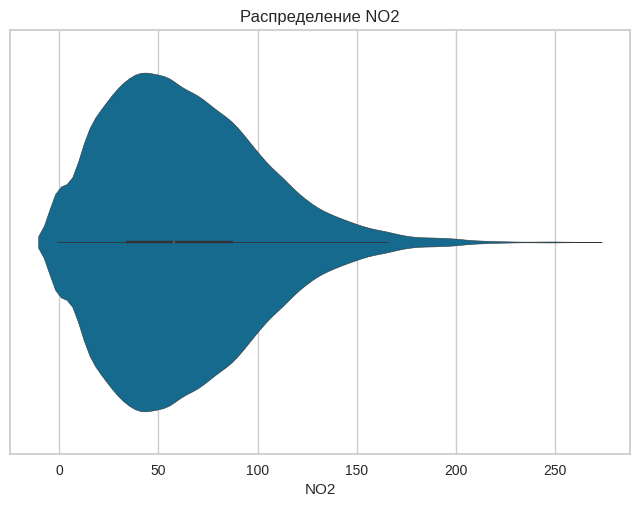

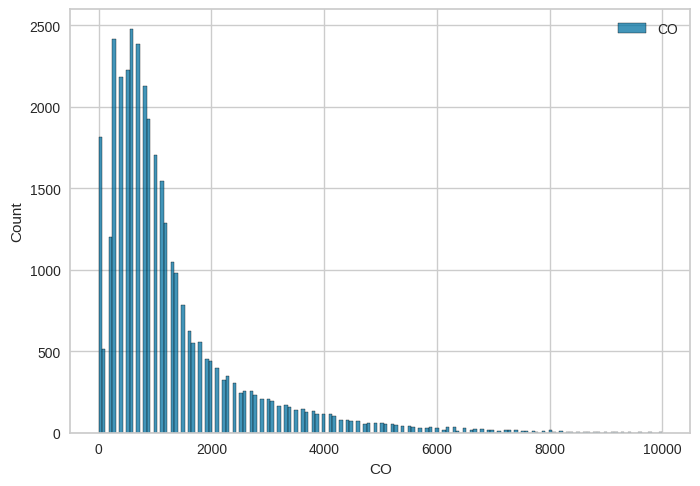

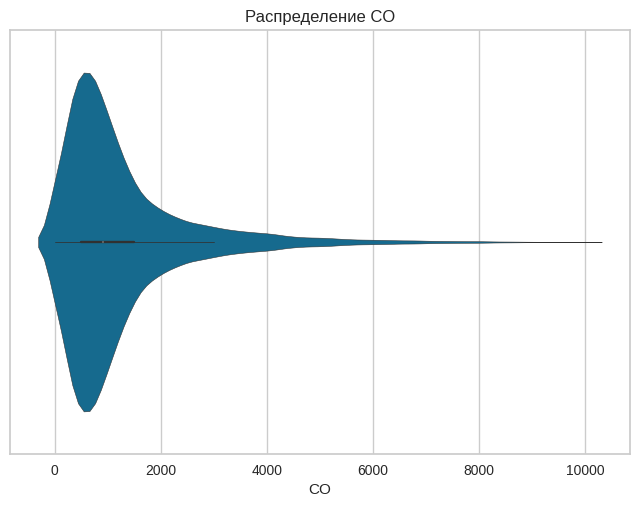

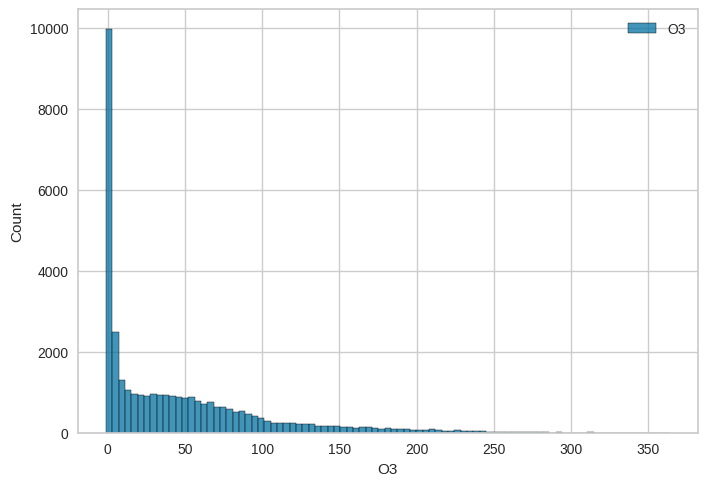

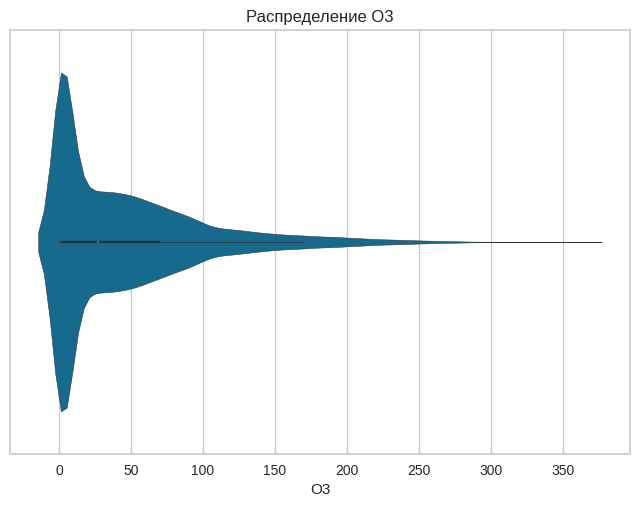

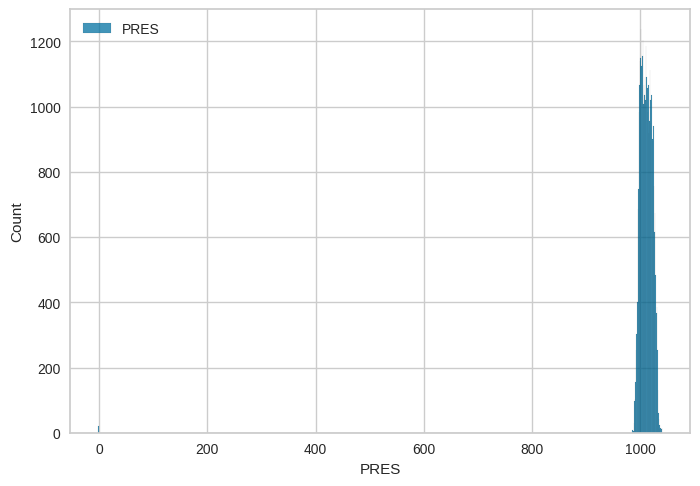

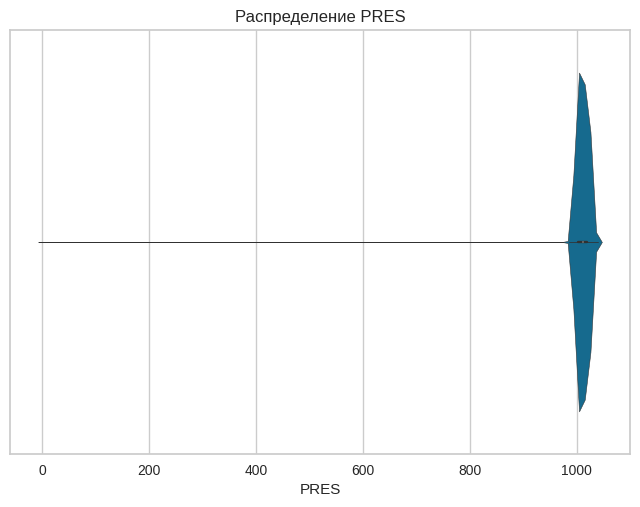

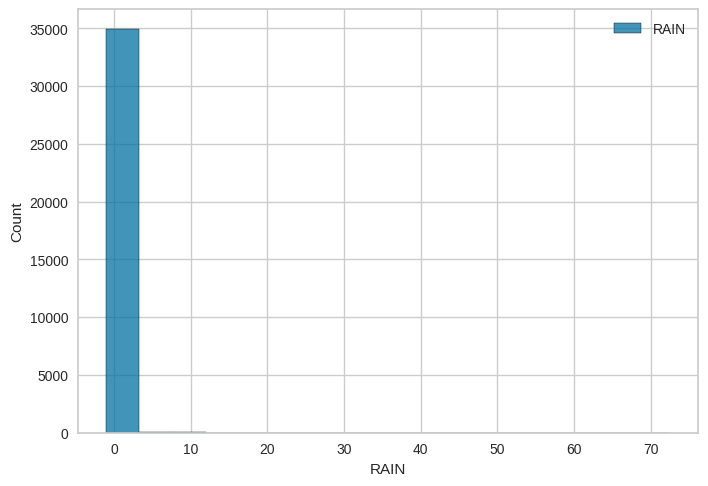

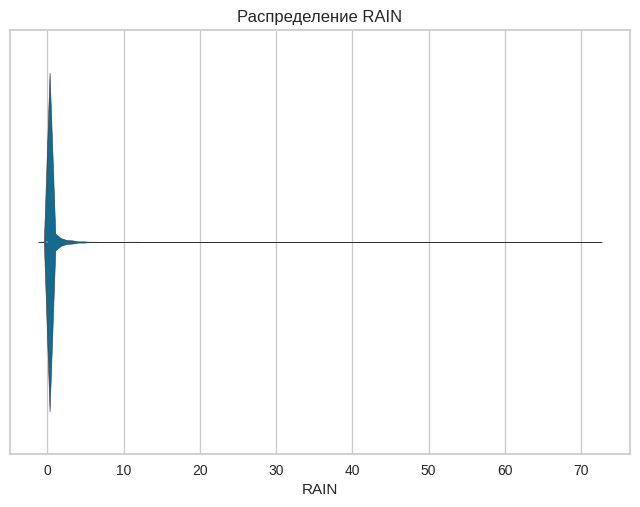

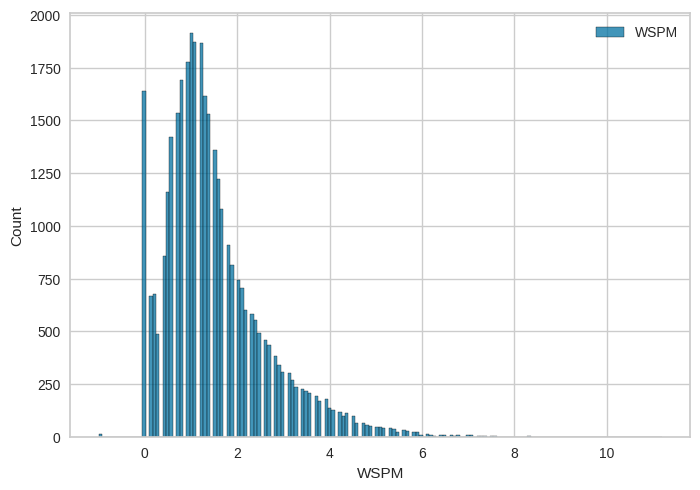

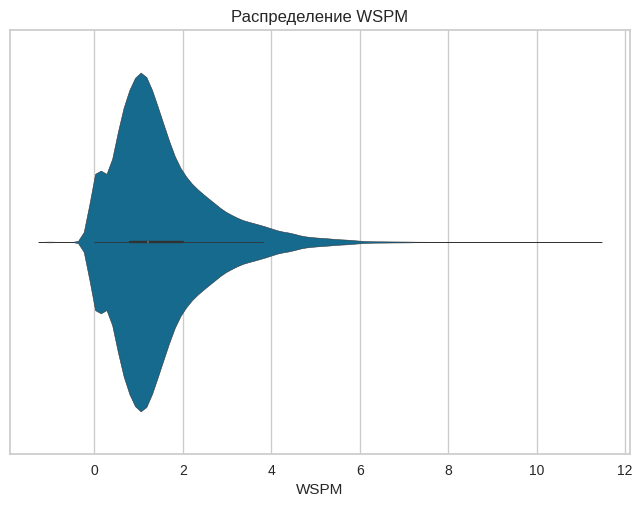

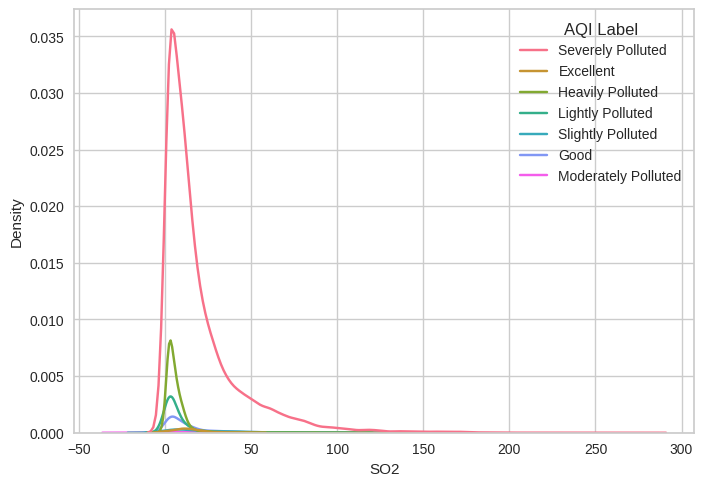

In [ ]:
#prsa_data = pd.read_csv("https://github.com/koroteevmv/ML_course/raw/main/ML5.2%20numeric%20features/PRSA_Data.csv")
prsa_data = pd.read_csv('/content/PRSA_Data.csv')

display(prsa_data.info())

def plotting(df,name):
  sns.histplot(df[name],label=name);plt.legend();plt.show();
  sns.violinplot(x=prsa_data[name]); # по X значения, по Y частота
  plt.title(f'Распределение {name}');
  plt.show();

names =[\
'SO2',
'NO2',
'CO',
'O3',
'PRES',
'RAIN',
'WSPM'\
 ]

for i in names:
  plotting(prsa_data,i)
sns.kdeplot(data=prsa_data, x="SO2", hue="AQI Label");plt.show()

plt.show()

# 2. При выполнении 6 задания мы явно подбирали руками границы диапазона для клиппинга. Реализуйте адаптивный клиппинг через процентили.

Удалите или ограничьте экстремальные значения атрибутов.

In [ ]:
#prsa_data.PRES[prsa_data.PRES <= 992] = 992
#prsa_data.PRES[prsa_data.PRES >= 1034] = 1034
def clipping(df, name):
  l = df[name].quantile(0.25)
  r = df[name].quantile(0.75)
  # межквартильный
  IQR = r-l
  low = l - 1.5*IQR
  high= r + 1.5*IQR
  return df[(df[name]>=low)&(df[name]<=high)]

clipping(prsa_data,'PRES')

,Unnamed: 0,No,SO2,NO2,CO,O3,PRES,RAIN,wd,WSPM,AQI Label
0,0,1,6.0,28.0,400.0,51.577659,1023.0,0.0,NNW,4.4,Severely Polluted
1,1,2,6.0,28.0,400.0,50.403851,1023.2,0.0,N,4.7,Severely Polluted
2,2,3,-1.0,19.0,400.0,54.923321,1023.5,0.0,NNW,5.6,Severely Polluted
3,3,4,8.0,14.0,-1.0,-1.000000,1024.5,0.0,NW,3.1,Excellent
4,4,5,9.0,-1.0,300.0,54.296608,1025.2,0.0,N,2.0,Heavily Polluted
...,...,...,...,...,...,...,...,...,...,...,...
35059,35059,35060,4.0,20.0,300.0,81.053452,1011.9,0.0,N,2.0,Heavily Polluted
35060,35060,35061,6.0,55.0,500.0,44.645126,1012.3,0.0,WSW,1.0,Severely Polluted
35061,35061,35062,7.0,48.0,500.0,47.567265,1012.8,0.0,N,1.1,Severely Polluted
35062,35062,35063,5.0,47.0,500.0,49.764297,1012.9,0.0,NNE,1.0,Severely Polluted


# 3. Избавьтесь от оставшихся пропусков в данных. Самостоятельно выберите метод.

In [ ]:
prsa_data.fillna(prsa_data.median)

,Unnamed: 0,No,SO2,NO2,CO,O3,PRES,RAIN,wd,WSPM,AQI Label
0,0,1,6.0,28.0,400.0,51.577659,1023.0,0.0,NNW,4.4,Severely Polluted
1,1,2,6.0,28.0,400.0,50.403851,1023.2,0.0,N,4.7,Severely Polluted
2,2,3,-1.0,19.0,400.0,54.923321,1023.5,0.0,NNW,5.6,Severely Polluted
3,3,4,8.0,14.0,-1.0,-1.000000,1024.5,0.0,NW,3.1,Excellent
4,4,5,9.0,-1.0,300.0,54.296608,1025.2,0.0,N,2.0,Heavily Polluted
...,...,...,...,...,...,...,...,...,...,...,...
35059,35059,35060,4.0,20.0,300.0,81.053452,1011.9,0.0,N,2.0,Heavily Polluted
35060,35060,35061,6.0,55.0,500.0,44.645126,1012.3,0.0,WSW,1.0,Severely Polluted
35061,35061,35062,7.0,48.0,500.0,47.567265,1012.8,0.0,N,1.1,Severely Polluted
35062,35062,35063,5.0,47.0,500.0,49.764297,1012.9,0.0,NNE,1.0,Severely Polluted


# 4. Проведите нормализацию численных признаков. Выберите наиболее подходящий вид нормализации для каждого признака.

In [ ]:
df = prsa_data.select_dtypes(include=['int64', 'float64'])

# проведем нормализацию с помощью min-max
min_ = df.min(); max_ = df.max();
(df - min_) / (max_ - min_)

,Unnamed: 0,No,SO2,NO2,CO,O3,PRES,RAIN,WSPM
0,0.000000,0.000000,0.024735,0.109434,0.040096,0.144140,0.983386,0.013605,0.442623
1,0.000029,0.000029,0.024735,0.109434,0.040096,0.140922,0.983578,0.013605,0.467213
2,0.000057,0.000057,0.000000,0.075472,0.040096,0.153312,0.983866,0.013605,0.540984
3,0.000086,0.000086,0.031802,0.056604,0.000000,0.000000,0.984827,0.013605,0.336066
4,0.000114,0.000114,0.035336,0.000000,0.030097,0.151593,0.985499,0.013605,0.245902
...,...,...,...,...,...,...,...,...,...
35059,0.999886,0.999886,0.017668,0.079245,0.030097,0.224946,0.972726,0.013605,0.245902
35060,0.999914,0.999914,0.024735,0.211321,0.050095,0.125134,0.973111,0.013605,0.163934
35061,0.999943,0.999943,0.028269,0.184906,0.050095,0.133145,0.973591,0.013605,0.172131
35062,0.999971,0.999971,0.021201,0.181132,0.050095,0.139168,0.973687,0.013605,0.163934


# 5. Постройте кореллограмму по всем численным столбцам датасета. Сделайте вывод о значимости признаков.

<Axes: >

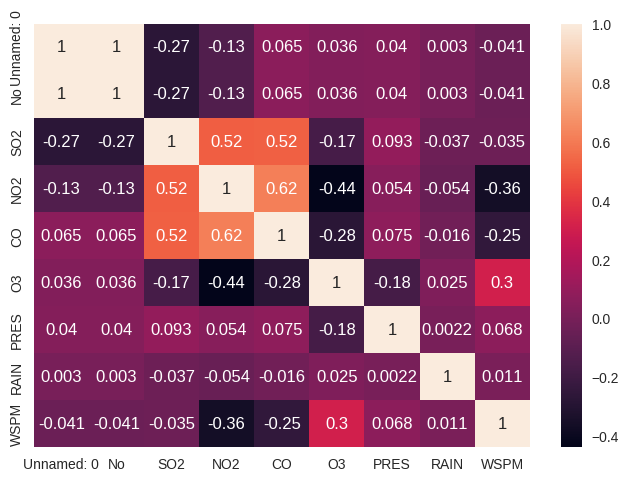

In [ ]:
df = prsa_data.select_dtypes(include=['int64', 'float64'])

sns.heatmap(df.corr(), annot = True)

# 6. Визуализируйте связи между признаками. Сделайте вывод об их взаимозависимости.

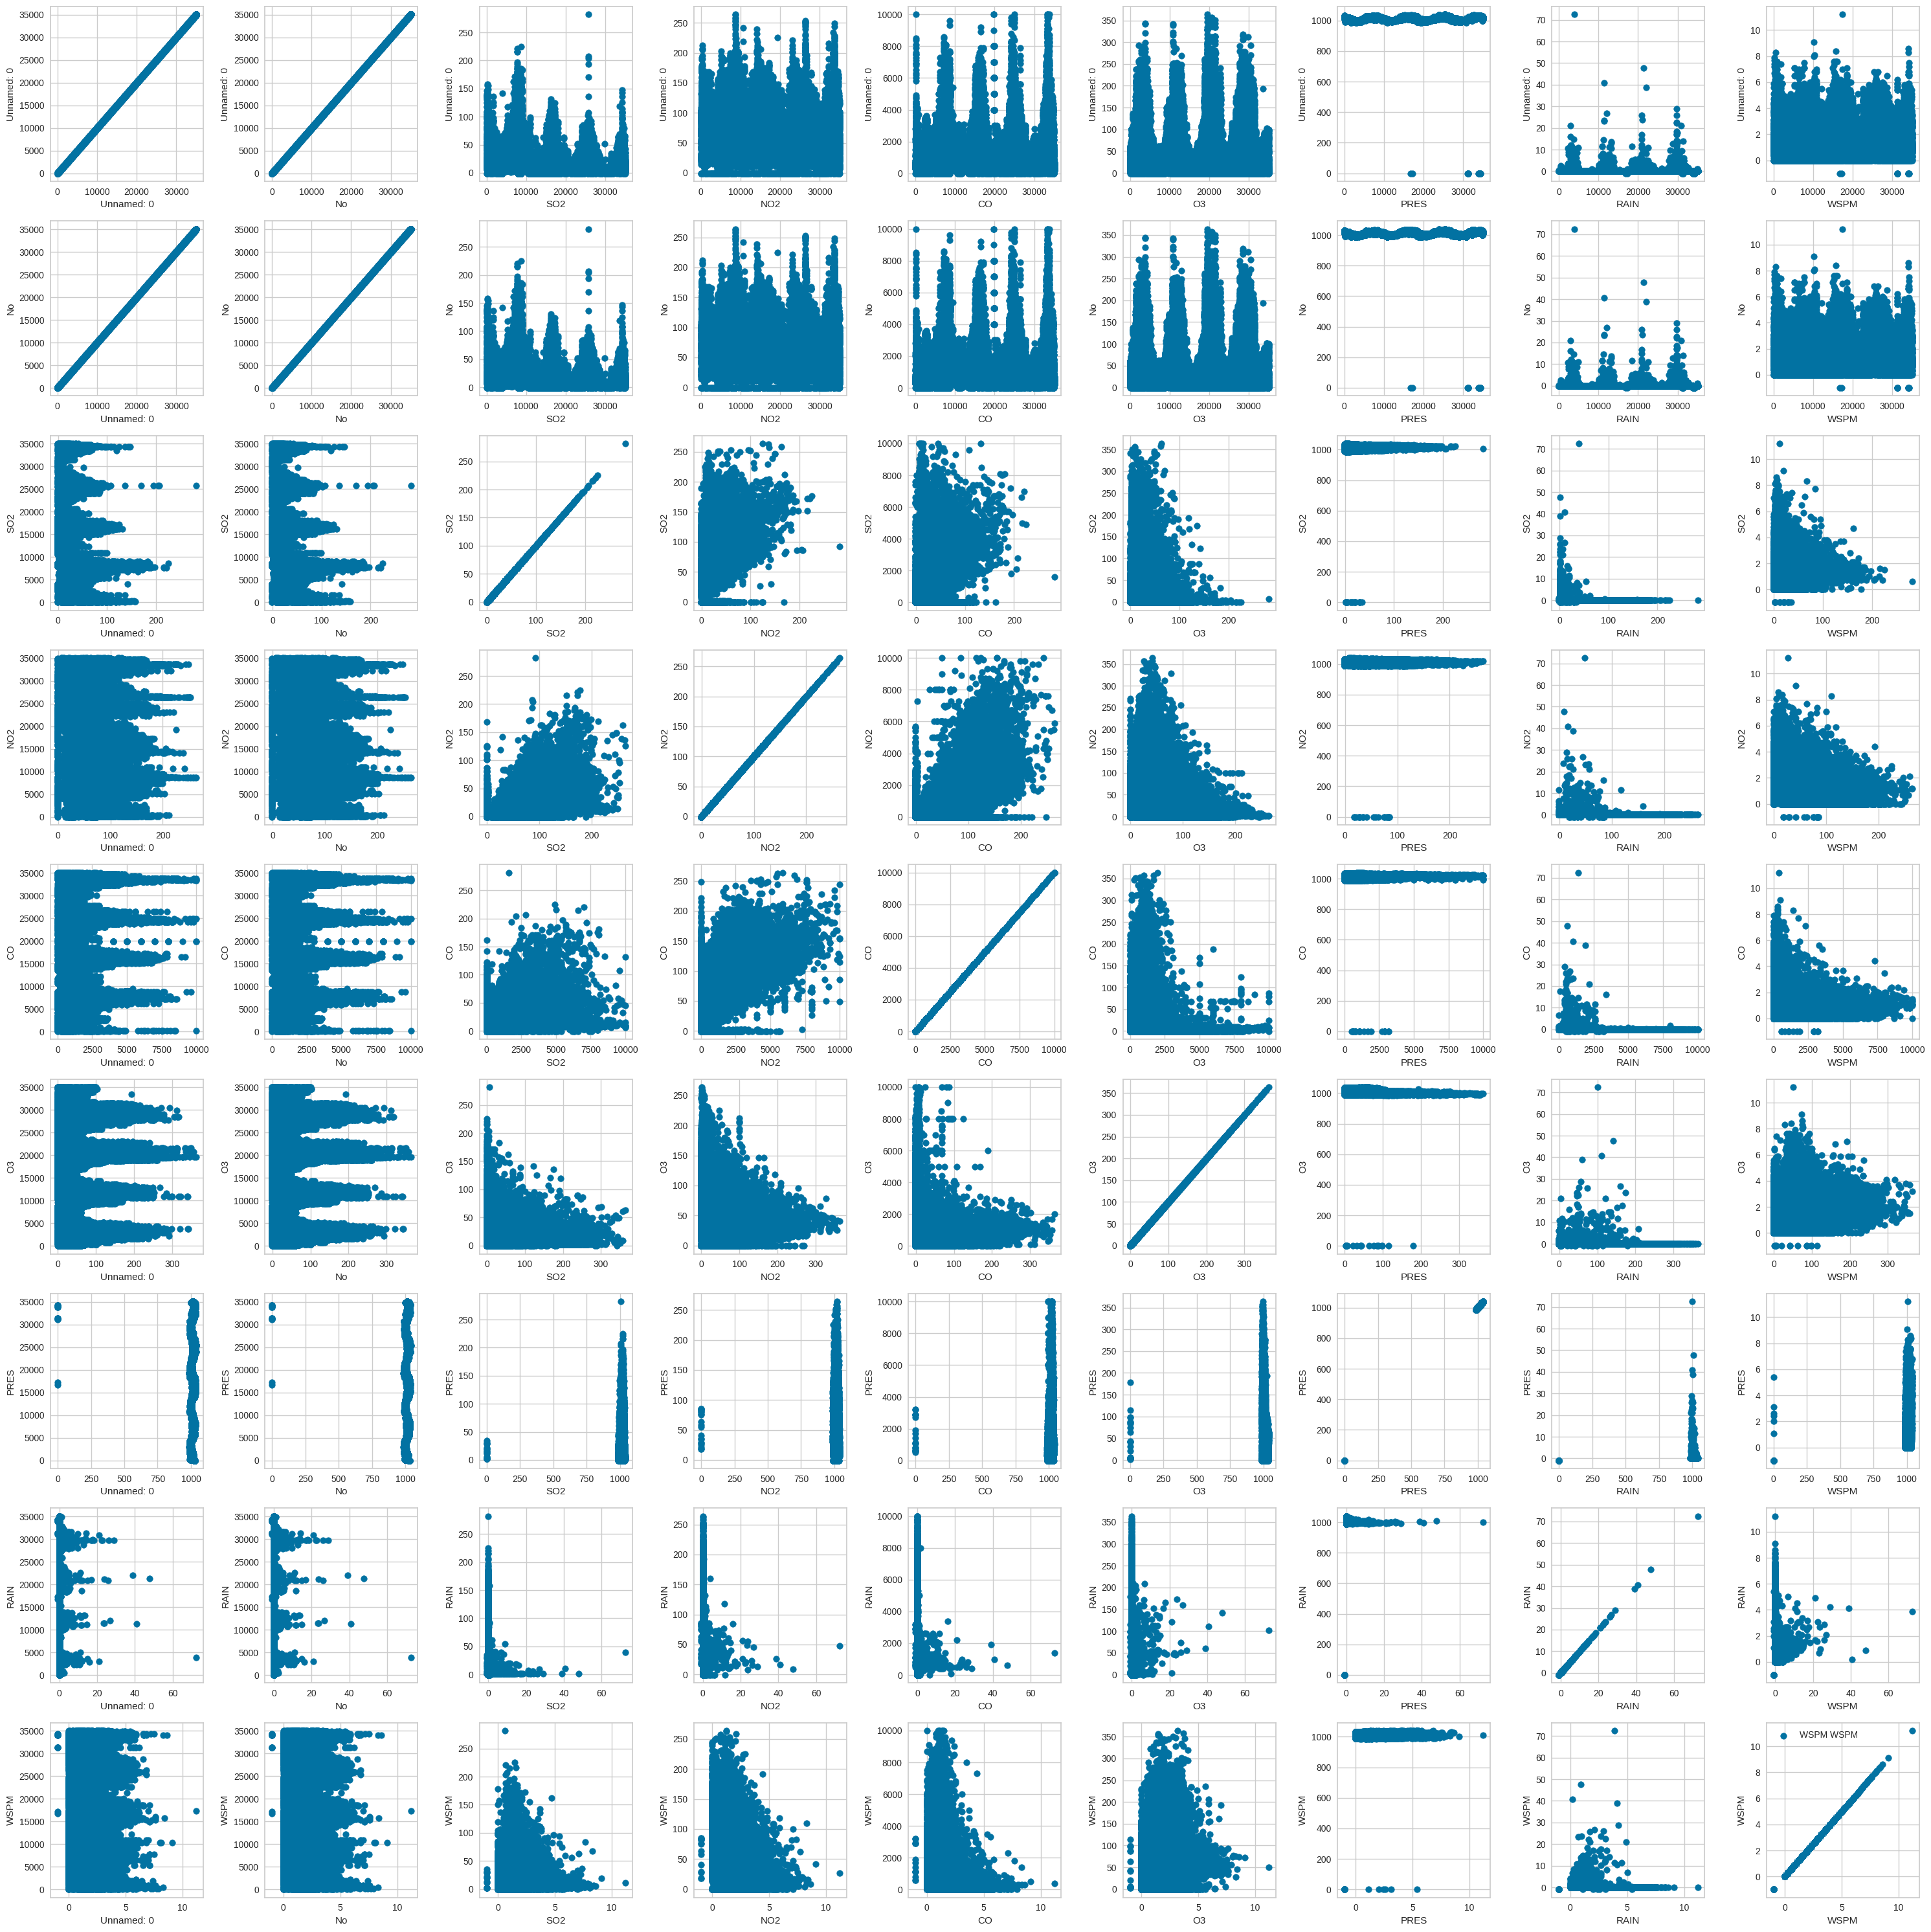

In [ ]:
fig,ax = plt.subplots(len(df.columns),len(df.columns),figsize=(30,30))
for k1,i in enumerate(df.columns):
  for k2,j in enumerate(df.columns):
    ax[k1][k2].scatter(df[i],df[j],label = f'{i} {j}')
    ax[k1, k2].set_xlabel(j)
    ax[k1, k2].set_ylabel(i)
plt.legend()
plt.tight_layout()
plt.show()

# 1. В данной работе проверьте целесообразность каждого необязательного преобразования данных путем проверки, увеличивает ли данное преобразование точность модели. Проверьте на простом виде модели (логит регрессия, дерево решений или случайный лес).


Исходя из распределения атрибутов по необходимости примените бинаризацию численных признаков.

Удалите или ограничьте экстремальные значения атрибутов.

Избавьтесь от пропущенных значений в датасете.

При необходимости округлите излишне точные значения атрибутов.

Рассмотрите возможность преобразования шкалы атрибута к логарифмической.

In [ ]:
models = [LR(),DTC(),RFC()]

df = prsa_data.select_dtypes(include=['int64', 'float64'])

def show_colored(top):
    for model, results in top.items():
        df = pd.DataFrame(results, columns=['Score', 'Fill', 'Scale'])
        styled = df.style.background_gradient(
            subset=['Score'], cmap='RdYlGn', vmin=0, vmax=1
        ).set_caption(f'Top-{df.shape[1]} scores for {model}')
        display(styled)

def clipping(df, name):
  l = df[name].quantile(0.25)
  r = df[name].quantile(0.75)
  # межквартильный
  IQR = r-l
  low = l - 1.5*IQR
  high= r + 1.5*IQR
  return df[(df[name]>=low)&(df[name]<=high)]

def min_max(df):
  min_ = df.min(); max_ = df.max();
  return (df - min_) / (max_ - min_)

def fillna_med(df):
  return df.fillna(df.median())

def fillna_zeros(df):
  return df.fillna(0)

def dropna(df):
  return df.dropna()

do_nothing = lambda x: x

model_names = ['LR', 'DTC', 'RFC']
fill_funcs  = [fillna_med, fillna_zeros, dropna]
scale_funcs = [do_nothing, min_max]


best_scores = {name: [] for name in model_names}

X = prsa_data.select_dtypes(include=['int64', 'float64'])
y = prsa_data['AQI Label']
from itertools import product
for fill_f, scale_f in product(fill_funcs, scale_funcs):
    #try:
        df_ = fill_f(X)
        if df_.isnull().values.any(): continue  # на случай if dropna не удалил все
        df_ = scale_f(df_)

        if len(df_) != len(y):
            y_ = y.loc[df_.index]
        else:
            y_ = y

        for model, name in zip(models, model_names):
            score = cross_val_score(model, df_, y_, cv=5).mean()
            best_scores[name].append((score, fill_f.__name__, scale_f.__name__))
    #except Exception: print('окак');continue

# Сортировка по убыванию
for name in best_scores:
    best_scores[name].sort(reverse=True)

# Топ-3 по каждому
top3 = {name: best_scores[name][:3] for name in best_scores}
show_colored(top3)

,Score,Fill,Scale
0,0.866388,fillna_zeros,
1,0.866388,fillna_med,
2,0.866388,dropna,


,Score,Fill,Scale
0,0.915011,fillna_zeros,
1,0.914213,dropna,min_max
2,0.913956,dropna,


,Score,Fill,Scale
0,0.922313,dropna,min_max
1,0.920488,fillna_zeros,
2,0.918690,fillna_med,min_max


# 2. Проанализируйте эффективность использования различных методов заполнения пропущенных значений.

In [ ]:
models = [LR(),DTC(),RFC()]

df = prsa_data.select_dtypes(include=['int64', 'float64'])

def show_colored(top):
    for model, results in top.items():
        df = pd.DataFrame(results, columns=['Score', 'Fill'])
        styled = df.style.background_gradient(
            subset=['Score'], cmap='RdYlGn', vmin=0, vmax=1
        ).set_caption(f'Top-{df.shape[1]} scores for {model}')
        display(styled)


def fillna_med(df):
  return df.fillna(df.median())

def fillna_zeros(df):
  return df.fillna(0)

def dropna(df):
  return df.dropna()


model_names = ['LR', 'DTC', 'RFC']
fill_funcs  = [fillna_med, fillna_zeros, dropna]

best_scores = {name: [] for name in model_names}


X = prsa_data.select_dtypes(include=['int64', 'float64'])
y = prsa_data['AQI Label']
from itertools import product
for fill_f in fill_funcs:
    #try:
        df_ = fill_f(X)
        if df_.isnull().values.any(): continue

        if len(df_) != len(y):
            y_ = y.loc[df_.index]
        else:
            y_ = y

        for model, name in zip(models, model_names):
            score = cross_val_score(model, df_, y_, cv=5).mean()
            best_scores[name].append((score, fill_f.__name__))
    #except Exception: print('окак');continue

# Сортировка по убыванию
for name in best_scores:
    best_scores[name].sort(reverse=True)

# Топ-3 по каждому
top3 = {name: best_scores[name][:3] for name in best_scores}
show_colored(top3)

,Score,Fill
0,0.866388,fillna_zeros
1,0.866388,fillna_med
2,0.866388,dropna


,Score,Fill
0,0.913357,fillna_zeros
1,0.913357,dropna
2,0.913214,fillna_med


,Score,Fill
0,0.919803,dropna
1,0.898157,fillna_zeros
2,0.880020,fillna_med


# 3. Попробуйте придумать другие методы инжиниринга признаков в этом датасете. Оцените их эффект по какой-то модели.

In [ ]:
def binarize_o3(df):
    df = df.copy()
    df['O3'] = (df['O3'] != 0).astype(int)
    return df

def binarize_so2_median(df):
    df = df.copy()
    med = df['SO2'].median()
    df['SO2'] = (df['SO2'] > med).astype(int)
    return df

def clip_pres_iqr(df):
    df = df.copy()
    q1 = df['PRES'].quantile(0.25)
    q3 = df['PRES'].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    return df[(df['PRES'] >= low) & (df['PRES'] <= high)]

def binarize_rain(df):
    df = df.copy()
    df['RAIN'] = (df['RAIN'] != 0).astype(int)
    return df

def show_colored(top):
    for model, results in top.items():
        df = pd.DataFrame(results, columns=['Score', 'methods'])
        styled = df.style.background_gradient(
            subset=['Score'], cmap='RdYlGn', vmin=0, vmax=1
        ).set_caption(f'Top-{df.shape[1]} scores for {model}')
        display(styled)

models = [LR(),DTC(),RFC()]
model_names = ['LR', 'DTC', 'RFC']

feat_eng  = [binarize_o3, binarize_so2_median, clip_pres_iqr, binarize_rain]

best_scores = {name: [] for name in model_names}

df = prsa_data.fillna(prsa_data.median)
#X = df.select_dtypes(include=['int64', 'float64'])
#y = df['AQI Label']

from itertools import permutations
for feat in permutations(feat_eng):
    #try:
        #df_ = X.copy()
        df_ = df.copy()

        for j in feat:
          df_ = j(df_)

        y = df_['AQI Label']
        df_ = df_.select_dtypes(include=['int64', 'float64'])

        if len(df_) != len(y):
            y_ = y.loc[df_.index]
        else:
            y_ = y

        for model, name in zip(models, model_names):
            score = cross_val_score(model, df_, y_, cv=5).mean()
            best_scores[name].append((score, [i.__name__ for i in feat]))

    #except: print('окак');continue

# Сортировка по убыванию
for name in best_scores:
    best_scores[name].sort(reverse=True)

# Топ-3 по каждому
top3 = {name: best_scores[name][:3] for name in best_scores}
show_colored(top3)

,Score,methods
0,0.857665,"['clip_pres_iqr', 'binarize_so2_median', 'binarize_rain', 'binarize_o3']"
1,0.857665,"['clip_pres_iqr', 'binarize_so2_median', 'binarize_o3', 'binarize_rain']"
2,0.857665,"['clip_pres_iqr', 'binarize_rain', 'binarize_so2_median', 'binarize_o3']"


,Score,methods
0,0.910654,"['clip_pres_iqr', 'binarize_o3', 'binarize_rain', 'binarize_so2_median']"
1,0.910226,"['binarize_rain', 'binarize_o3', 'clip_pres_iqr', 'binarize_so2_median']"
2,0.910169,"['binarize_rain', 'binarize_so2_median', 'binarize_o3', 'clip_pres_iqr']"


,Score,methods
0,0.919587,"['binarize_o3', 'clip_pres_iqr', 'binarize_rain', 'binarize_so2_median']"
1,0.918274,"['binarize_o3', 'binarize_so2_median', 'binarize_rain', 'clip_pres_iqr']"
2,0.917760,"['binarize_so2_median', 'clip_pres_iqr', 'binarize_rain', 'binarize_o3']"


# 4. Перед началом обработки данных разбейте датасет на тестовую и обучающую выборки. Очистите по методу из работы обучающую выборку. Повторите обработку на тестовой выборке. При этом позаботьтесь, чтобы все параметрические преобразования (клиппинг, нормализация, группировка и так далее).

In [ ]:
prsa_data[prsa_data == -1] = np.nan
prsa_data.RAIN[prsa_data.RAIN > 0]
is_rain = np.array(prsa_data.RAIN)
is_rain[is_rain > 0] = 1
prsa_data['IS_RAIN'] = is_rain
prsa_data.drop(['RAIN'], axis=1, inplace=True)
bin_ranges = [0, 250, 320, 10000]
bin_names = [1, 2, 3]
prsa_data['CO_bin_custom_label'] = pd.cut(np.array(prsa_data['CO']),
                                               bins=bin_ranges, labels=bin_names)
prsa_data['CO_bin_custom_label'] = prsa_data['CO_bin_custom_label'].values.add_categories(0)
prsa_data['CO_bin_custom_label'] = prsa_data['CO_bin_custom_label'].fillna(0).astype(int)
prsa_data.PRES[prsa_data.PRES <= 992] = 992
prsa_data.PRES[prsa_data.PRES >= 1034] = 1034
undef = prsa_data.isnull().sum(axis=1)
prsa_data = prsa_data.drop(undef[undef >= 2].index, axis=0)
prsa_data.SO2 = prsa_data.SO2.fillna(prsa_data.PRES.mean())
filler = prsa_data.O3[prsa_data.O3.isna()]
filler = prsa_data.O3[~prsa_data.O3.isna()].sample(n=len(filler)).set_axis(filler.index)
prsa_data.O3 = prsa_data.O3.fillna(filler)
prsa_data['O3'] = np.array(np.round((prsa_data['O3'])), dtype='int')
prsa_data.SO2 = np.log(prsa_data.SO2)

In [ ]:
# 1. Разделение до любой обработки
train, test = train_test_split(prsa_data, test_size=0.2, random_state=42)

# 2. Описание параметров с train
# Клиппинг PRES (визуально можно отметить что есть выбросы по значениям)
q1, q3 = train['PRES'].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
train = train[(train['PRES'] >= low) & (train['PRES'] <= high)]

# Binning RAIN (сильно контрастные значения, пусть будет "есть/нет")
train['IS_RAIN'] = (train['RAIN'] > 0).astype(int)
test['IS_RAIN'] = (test['RAIN'] > 0).astype(int)
train.drop(columns=['RAIN'], inplace=True)
test.drop(columns=['RAIN'], inplace=True)

# Binning CO по обучающей медианам
bin_ranges = [0, 250, 320, 10000]
bin_names = [1, 2, 3]
train['CO_bin_custom_label'] = pd.cut(train['CO'], bins=bin_ranges, labels=bin_names)
train['CO_bin_custom_label'] = train['CO_bin_custom_label'].cat.add_categories(0).fillna(0).astype(int)

test['CO_bin_custom_label'] = pd.cut(test['CO'], bins=bin_ranges, labels=bin_names)
test['CO_bin_custom_label'] = test['CO_bin_custom_label'].cat.add_categories(0).fillna(0).astype(int)

# Ограничение PRES
train['PRES'] = train['PRES'].clip(lower=992, upper=1034)
test['PRES'] = test['PRES'].clip(lower=992, upper=1034)

# Удаление строк с >=2 пропусками
train = train[train.isnull().sum(axis=1) < 2]
test = test[test.isnull().sum(axis=1) < 2]

# Заполнение SO2 медианой PRES
so2_fill = train['PRES'].mean()
train['SO2'] = train['SO2'].fillna(so2_fill)
test['SO2'] = test['SO2'].fillna(so2_fill)

# Заполнение O3 случайной выборкой из train
filler = train['O3'].dropna()
train['O3'] = train['O3'].fillna(
    filler.sample(n=train['O3'].isna().sum(), random_state=42).set_axis(train['O3'][train['O3'].isna()].index)
)
test['O3'] = test['O3'].fillna(
    filler.sample(n=test['O3'].isna().sum(), random_state=42).set_axis(test['O3'][test['O3'].isna()].index)
)

# Округление O3
train['O3'] = np.round(train['O3']).astype(int)
test['O3'] = np.round(test['O3']).astype(int)

# Логарифмирование SO2
train['SO2'] = np.log(train['SO2'])
test['SO2'] = np.log(test['SO2'])


# 5. Создайте воспроизводимый код обработки данного датасета.

In [ ]:
# 1. Разделение до любой обработки
train, test = train_test_split(prsa_data, test_size=0.2, random_state=42)

# 2. Описание параметров с train
# Клиппинг PRES
q1, q3 = train['PRES'].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
train = train[(train['PRES'] >= low) & (train['PRES'] <= high)]

# Обработка RAIN
train['IS_RAIN'] = (train['RAIN'] > 0).astype(int)
test['IS_RAIN'] = (test['RAIN'] > 0).astype(int)
train.drop(columns=['RAIN'], inplace=True)
test.drop(columns=['RAIN'], inplace=True)

# Binning CO по обучающей медианам
bin_ranges = [0, 250, 320, 10000]
bin_names = [1, 2, 3]
train['CO_bin_custom_label'] = pd.cut(train['CO'], bins=bin_ranges, labels=bin_names)
train['CO_bin_custom_label'] = train['CO_bin_custom_label'].cat.add_categories(0).fillna(0).astype(int)

test['CO_bin_custom_label'] = pd.cut(test['CO'], bins=bin_ranges, labels=bin_names)
test['CO_bin_custom_label'] = test['CO_bin_custom_label'].cat.add_categories(0).fillna(0).astype(int)

# Ограничение PRES
train['PRES'] = train['PRES'].clip(lower=992, upper=1034)
test['PRES'] = test['PRES'].clip(lower=992, upper=1034)

# Удаление строк с >=2 пропусками
train = train[train.isnull().sum(axis=1) < 2]
test = test[test.isnull().sum(axis=1) < 2]

# Заполнение SO2 медианой PRES
so2_fill = train['PRES'].mean()
train['SO2'] = train['SO2'].fillna(so2_fill)
test['SO2'] = test['SO2'].fillna(so2_fill)

# Заполнение O3 случайной выборкой из train
filler = train['O3'].dropna()
train['O3'] = train['O3'].fillna(
    filler.sample(n=train['O3'].isna().sum(), random_state=42).set_axis(train['O3'][train['O3'].isna()].index)
)
test['O3'] = test['O3'].fillna(
    filler.sample(n=test['O3'].isna().sum(), random_state=42).set_axis(test['O3'][test['O3'].isna()].index)
)

# Округление O3
train['O3'] = np.round(train['O3']).astype(int)
test['O3'] = np.round(test['O3']).astype(int)

# Логарифмирование SO2
train['SO2'] = np.log(train['SO2'])
test['SO2'] = np.log(test['SO2'])

# 6. В датасете Customer_support, который стал результатом выполнения предыдущей работы преобразуйте все даты в абсолютные признаки. Извлеките из дат значимую информацию - день недели, время дня, день месяца. Составьте значимые временные промежутки.

In [ ]:
data1 = pd.read_csv('issues1.csv', index_col=0)
data2 = pd.read_csv('issues2.csv', index_col=0)
data3 = pd.read_csv('issues4.csv', index_col=0)
data2 = data2.rename(columns={
    'channel_name': 'Channel',
    'Reported at': 'Issue_reported_Date',
    'Responded at': 'Issue_responded_Date',
    'Survey responded at': 'Survey_response_Date',
})
data2['Issue_reported_Date'] = pd.to_datetime(data2['Issue_reported_Date'])
data2['Issue_responded_Date'] = pd.to_datetime(data2['Issue_responded_Date'])
data2['Survey_response_Date'] = pd.to_datetime(data2['Survey_response_Date'], format='%d %m %Y')
data1['Issue_reported_Date'] = pd.to_datetime(data1['Issue_reported_Date'], dayfirst=True)
data1['Issue_responded_Date'] = pd.to_datetime(data1['Issue_responded_Date'], dayfirst=True)
data1['Survey_response_Date'] = pd.to_datetime(data1['Survey_response_Date'], format='%d-%b-%y')
data_12 = pd.concat([data1, data2])
data3 = data3.rename(columns={
    'Unique id': 'Id',
    'channel_name': 'Channel',
    'Issue_reported at': 'Issue_reported_Date',
    'issue_responded': 'Issue_responded_Date',
    'Survey responded at': 'Survey_response_Date',
    'Agent': 'Agent_name'
})
data3['Issue_reported_Date'] = pd.to_datetime(data3['Issue_reported_Date'])
data3['Issue_responded_Date'] = pd.to_datetime(data3['Issue_responded_Date'])
data3['Survey_response_Date'] = pd.to_datetime(data3['Survey_response_Date'])
data_123 = pd.concat([data_12, data3])
data3['Agent_name'] = data3['Agent_name'].apply(
    lambda x: x.split()[0][0] + ". " + x.split()[1] if isinstance(x, str) else np.NAN
)
data_123 = pd.concat([data_12, data3])
orders_data = pd.read_csv('orders.csv', index_col=0)
orders_data = orders_data.rename(columns={
    'Id': 'Order_id',
})
data_with_orders = data_123.merge(orders_data, on='Order_id', how='left')
agent_data = pd.read_csv("agents.csv", index_col=0)
agent_data['Agent_name'] = agent_data['Agent'].apply(
    lambda x: x.split()[0][0] + ". " + x.split()[1] if isinstance(x, str) else np.NAN
)
data_with_agents = data_with_orders.join(agent_data, rsuffix='_1', how='left')
data_with_agents = data_with_orders.merge(agent_data, how='left', on='Agent_name', copy=False)

In [ ]:
# Копия итогового датасета
data = data_with_agents.copy()

# Функция для преобразования одной даты
def expand_datetime(df, col):
    df[f'{col}_dayofweek'] = df[col].dt.dayofweek  # 0-пн, 6-вс
    df[f'{col}_hour'] = df[col].dt.hour
    df[f'{col}_day'] = df[col].dt.day
    return df

# Применение ко всем датам
for date_col in ['Issue_reported_Date', 'Issue_responded_Date', 'Survey_response_Date']:
    data = expand_datetime(data, date_col)

# Временные дельты (в днях и минутах)
data['Response_delay_days'] = (data['Issue_responded_Date'] - data['Issue_reported_Date']).dt.total_seconds() / 86400
data['Survey_delay_days'] = (data['Survey_response_Date'] - data['Issue_responded_Date']).dt.total_seconds() / 86400
data['Full_cycle_minutes'] = (data['Survey_response_Date'] - data['Issue_reported_Date']).dt.total_seconds() / 60

# Время суток (категориальный признак по часу)
def time_of_day(hour):
    if 6 <= hour < 12: return 'morning'
    if 12 <= hour < 17: return 'day'
    if 17 <= hour < 22: return 'evening'
    return 'night'

for col in ['Issue_reported_Date', 'Issue_responded_Date', 'Survey_response_Date']:
    data[f'{col}_time_of_day'] = data[f'{col}_hour'].apply(time_of_day)

customer_support = data
display(customer_support)

,Id,Channel,category,Sub-category,Customer Remarks,Order_id,Issue_reported_Date,Issue_responded_Date,Survey_response_Date,Agent_name,...,Issue_responded_Date_day,Survey_response_Date_dayofweek,Survey_response_Date_hour,Survey_response_Date_day,Response_delay_days,Survey_delay_days,Full_cycle_minutes,Issue_reported_Date_time_of_day,Issue_responded_Date_time_of_day,Survey_response_Date_time_of_day
0,8c910188-c387-4a1b-8d90-24379ec8c047,Inbound,Returns,Reverse Pickup Enquiry,Very happy,NaN,2023-08-04 19:10:00,2023-08-04 19:13:00,2023-08-04,J. Blackwell,...,4,4,0,4,0.002083,-0.800694,-1150.0,evening,evening,night
1,99d5ee06-8d2a-4754-bd17-ed235c70bf33,Inbound,Returns,Return request,Thoda jalfi replacement approve kijiye mera,89e6448f-9a48-4892-a09c-b47e0d8a87fe,2023-08-18 09:11:00,2023-08-18 09:18:00,2023-08-18,M. Wilson,...,18,4,0,18,0.004861,-0.387500,-551.0,morning,morning,night
2,336020c5-dc97-488f-8f16-ed33ed04e5fc,Inbound,Returns,Damaged,Technician not visit the RO and without visit ...,15476f9a-35cc-4f33-ae33-8d9cd6ecb1a6,2023-08-22 07:15:00,2023-08-22 08:15:00,2023-08-22,A. Smith,...,22,1,0,22,0.041667,-0.343750,-435.0,morning,morning,night
3,22c5643c-3d54-487c-8863-c57e198a70be,Inbound,Returns,Fraudulent User,madam ne mera problem solve kar Diya hai . t...,NaN,2023-08-14 09:21:00,2023-08-14 09:27:00,2023-08-14,A. Berry,...,14,0,0,14,0.004167,-0.393750,-561.0,morning,morning,night
4,abd330a8-f3e2-4b7a-b14a-4ed35c4ec023,Inbound,Returns,Fraudulent User,Gjjjzjxgxteuhxgxe5xhxh,NaN,2023-08-03 08:18:00,2023-08-03 08:23:00,2023-08-03,S. Taylor,...,3,3,0,3,0.003472,-0.349306,-498.0,morning,morning,night
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
111617,ea09d98a-63d4-4143-8035-0e92c468baca,Inbound,Payments related,Online Payment Issues,NaN,NaN,2023-08-16 15:10:00,2023-08-16 15:12:00,2023-08-16,K. Schultz,...,16,2,0,16,0.001389,-0.633333,-910.0,day,day,night
111618,ebf0a860-c06d-4a10-a631-43787004d7dc,Inbound,Returns,Reverse Pickup Enquiry,NaN,NaN,2023-08-15 16:16:00,2023-08-15 16:20:00,2023-08-15,B. Frost,...,15,1,0,15,0.002778,-0.680556,-976.0,day,day,night
111619,e5bd9747-3a7e-4c3e-8972-670fa338b4c8,Inbound,Order Related,Priority delivery,NaN,NaN,2023-08-27 16:23:00,2023-08-27 16:25:00,2023-08-27,D. Wright,...,27,6,0,27,0.001389,-0.684028,-983.0,day,day,night
111620,13bfa4ab-d0b2-455d-b5d4-dbbb8c4de450,Inbound,Returns,Reverse Pickup Enquiry,NaN,NaN,2023-03-08 14:51:00,2023-08-03 15:08:00,2023-08-03,M. Edwards,...,3,3,0,3,148.011806,-0.630556,212229.0,day,day,night


# 7. Повторите обработку численных параметров в датасете "Титаник".

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
0,1,0,3,22.0,1,0,7.2500
1,2,1,1,38.0,1,0,71.2833
2,3,1,3,26.0,0,0,7.9250
3,4,1,1,35.0,1,0,53.1000
4,5,0,3,35.0,0,0,8.0500
...,...,...,...,...,...,...,...
886,887,0,2,27.0,0,0,13.0000
887,888,1,1,19.0,0,0,30.0000
888,889,0,3,NaN,1,2,23.4500
889,890,1,1,26.0,0,0,30.0000


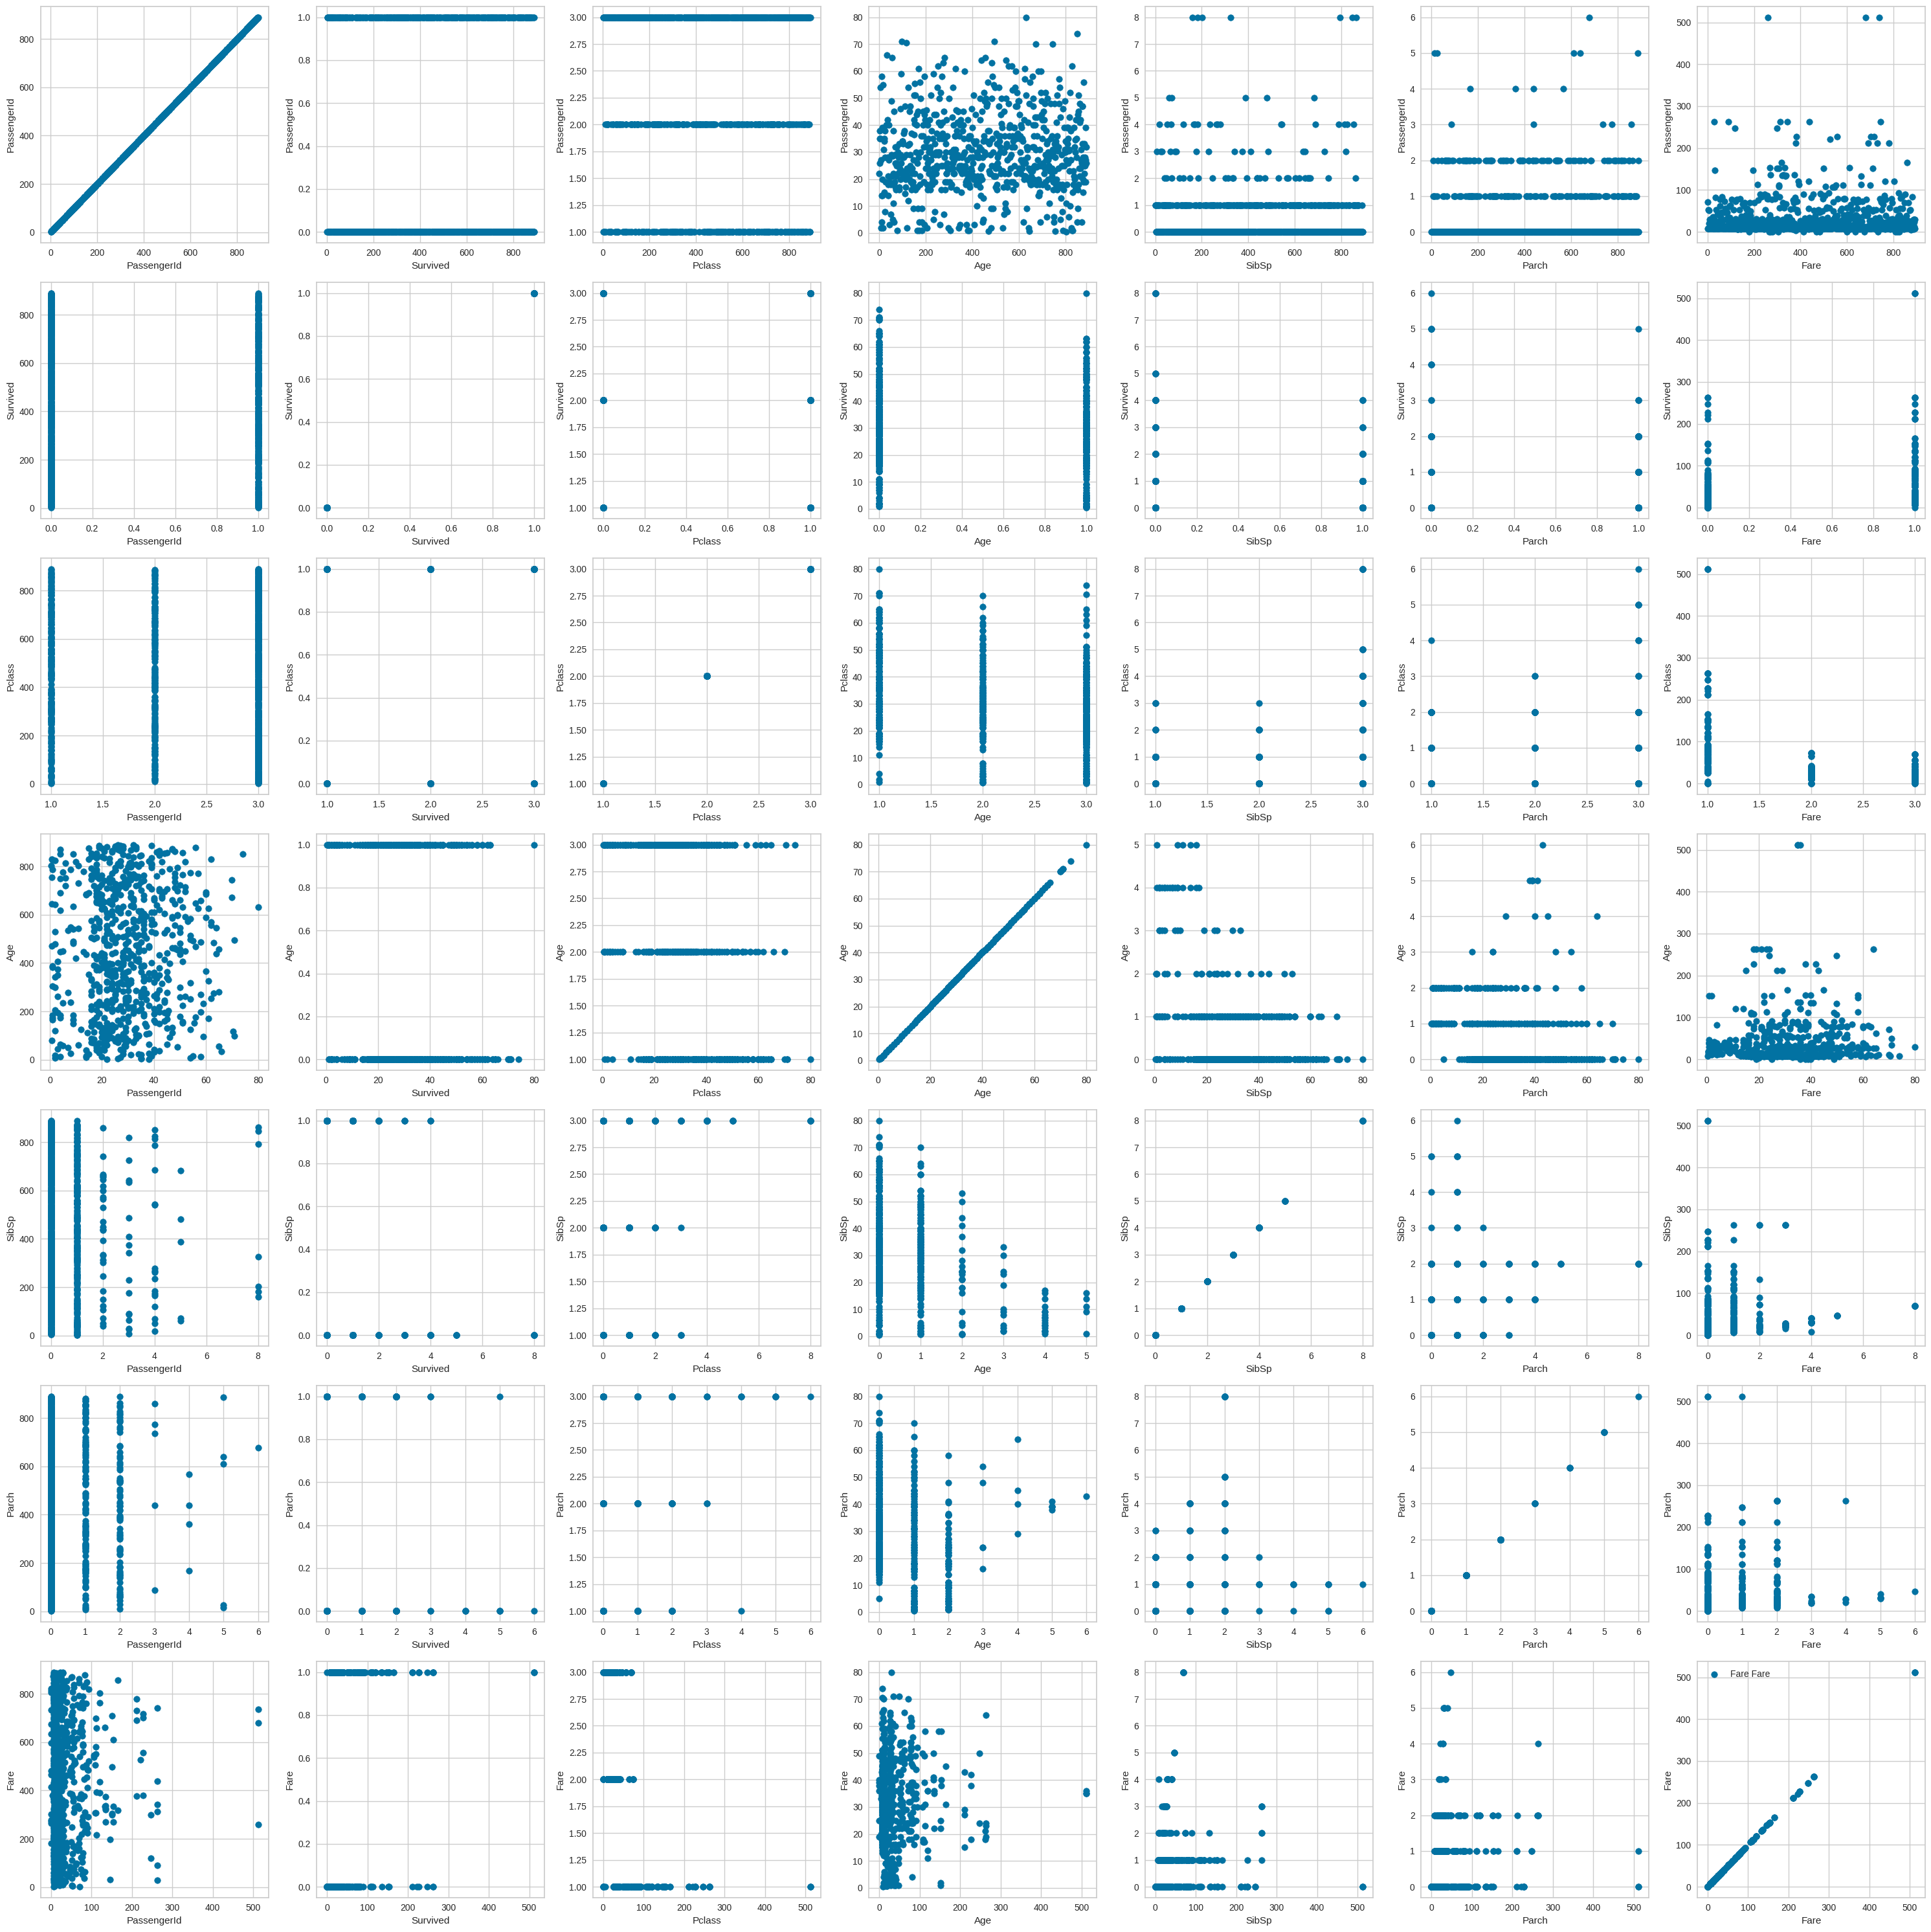

In [ ]:
titanic = pd.read_csv('/content/titanic.csv')
df = titanic.select_dtypes([np.int64,np.float64])
display(df)
fig,ax = plt.subplots(len(df.columns),len(df.columns),figsize=(30,30))
for k1,i in enumerate(df.columns):
  for k2,j in enumerate(df.columns):
    ax[k1][k2].scatter(df[i],df[j],label = f'{i} {j}')
    ax[k1, k2].set_xlabel(j)
    ax[k1, k2].set_ylabel(i)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
titanic.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [ ]:
[len(titanic[i].unique()) for i in titanic]

[891, 2, 3, 891, 2, 89, 7, 7, 681, 248, 148, 4]

In [ ]:
titanic = pd.read_csv('/content/titanic.csv')
titanic['Age'].fillna(titanic['Age'].median(), inplace=True)
titanic['Fare'].fillna(titanic['Fare'].mean(), inplace=True)
titanic['Embarked'].fillna(titanic['Embarked'].mode()[0], inplace=True)

#Sib — siblings
#Sp  — spouse
#Par — parents
#ch  — children
titanic['FamilySize'] = titanic['SibSp'] + titanic['Parch'] + 1
titanic['IsAlone'] = (titanic['FamilySize'] == 1).astype(int)
titanic['AgeGroup'] = pd.cut(titanic['Age'], bins=[0, 12, 18, 60, 100], labels=['Child', 'Teen', 'Adult', 'Elderly'])

# log1p <=> log(1+x), x+1 чтобы обработать если что x==0
titanic['LogFare'] = np.log1p(titanic['Fare'])

num_feat = ['Age', 'Fare', 'SibSp', 'Parch', 'FamilySize']
scaler = SC()
titanic[num_feat] = scaler.fit_transform(titanic[num_feat])

titanic = pd.get_dummies(titanic, columns=['Sex', 'Embarked', 'AgeGroup'], drop_first=True)

display(titanic.info())
display(titanic.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   PassengerId       891 non-null    int64  
 1   Survived          891 non-null    int64  
 2   Pclass            891 non-null    int64  
 3   Name              891 non-null    object 
 4   Age               891 non-null    float64
 5   SibSp             891 non-null    float64
 6   Parch             891 non-null    float64
 7   Ticket            891 non-null    object 
 8   Fare              891 non-null    float64
 9   Cabin             204 non-null    object 
 10  FamilySize        891 non-null    float64
 11  IsAlone           891 non-null    int64  
 12  LogFare           891 non-null    float64
 13  Sex_male          891 non-null    bool   
 14  Embarked_Q        891 non-null    bool   
 15  Embarked_S        891 non-null    bool   
 16  AgeGroup_Teen     891 non-null    bool   
 1

None

,PassengerId,Survived,Pclass,Name,Age,SibSp,Parch,Ticket,Fare,Cabin,FamilySize,IsAlone,LogFare,Sex_male,Embarked_Q,Embarked_S,AgeGroup_Teen,AgeGroup_Adult,AgeGroup_Elderly
0,1,0,3,"Braund, Mr. Owen Harris",-0.565736,0.432793,-0.473674,A/5 21171,-0.502445,NaN,0.059160,0,2.110213,True,False,True,False,True,False
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0.663861,0.432793,-0.473674,PC 17599,0.786845,C85,0.059160,0,4.280593,False,False,False,False,True,False
2,3,1,3,"Heikkinen, Miss. Laina",-0.258337,-0.474545,-0.473674,STON/O2. 3101282,-0.488854,NaN,-0.560975,1,2.188856,False,False,True,False,True,False
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0.433312,0.432793,-0.473674,113803,0.420730,C123,0.059160,0,3.990834,False,False,True,False,True,False
4,5,0,3,"Allen, Mr. William Henry",0.433312,-0.474545,-0.473674,373450,-0.486337,NaN,-0.560975,1,2.202765,True,False,True,False,True,False


# 8. (*) Создайте код, реализующий алгоритм очистки данных автоматически (для любого датасета).

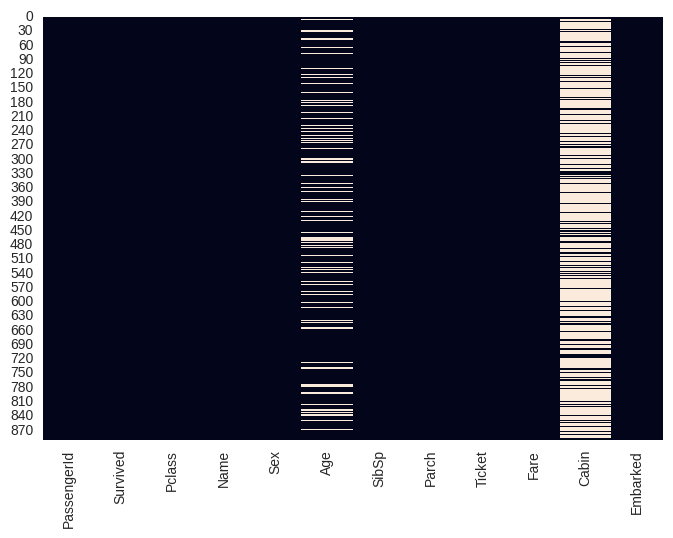

(891, 12)

<class 'pandas.core.frame.DataFrame'>
Index: 616 entries, 45 to 845
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  616 non-null    int64  
 1   Survived     616 non-null    int64  
 2   Pclass       616 non-null    int64  
 3   Name         616 non-null    object 
 4   Sex          616 non-null    object 
 5   Age          616 non-null    float64
 6   SibSp        616 non-null    int64  
 7   Parch        616 non-null    int64  
 8   Ticket       616 non-null    object 
 9   Fare         616 non-null    float64
 10  Embarked     616 non-null    object 
dtypes: float64(2), int64(5), object(4)
memory usage: 57.8+ KB


None

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
45,46,0,3,"Rogers, Mr. William John",male,28.0,0,0,S.C./A.4. 23567,8.0500,S
46,47,0,3,"Lennon, Mr. Denis",male,28.0,1,0,370371,15.5000,Q
47,48,1,3,"O'Driscoll, Miss. Bridget",female,28.0,0,0,14311,7.7500,Q
48,49,0,3,"Samaan, Mr. Youssef",male,28.0,2,0,2662,21.6792,C
49,50,0,3,"Arnold-Franchi, Mrs. Josef (Josefine Franchi)",female,18.0,1,0,349237,17.8000,S
...,...,...,...,...,...,...,...,...,...,...,...
840,841,0,3,"Alhomaki, Mr. Ilmari Rudolf",male,20.0,0,0,SOTON/O2 3101287,7.9250,S
841,842,0,2,"Mudd, Mr. Thomas Charles",male,16.0,0,0,S.O./P.P. 3,10.5000,S
842,843,1,1,"Serepeca, Miss. Augusta",female,30.0,0,0,113798,31.0000,C
844,845,0,3,"Culumovic, Mr. Jeso",male,17.0,0,0,315090,8.6625,S


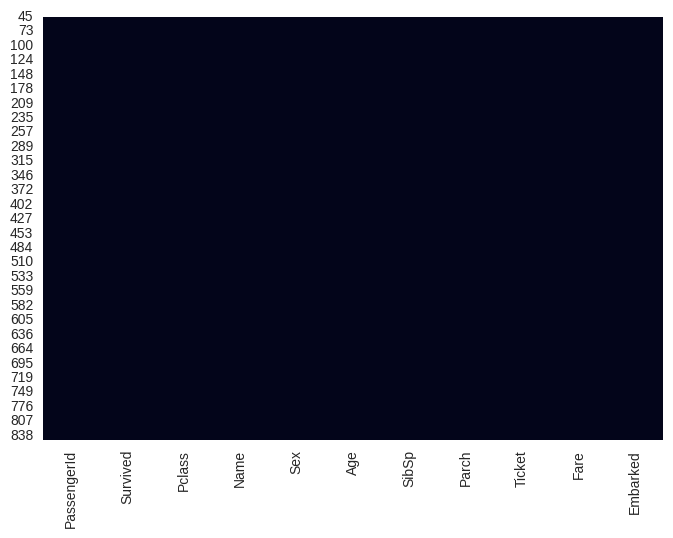

(616, 11)

In [ ]:
def auto_clean(df, quant = 0.75, drop_half = True):
    if drop_half:
      # просто дропнем все признаки которые в которых нет и половины заполненных строк
      df = df.dropna(axis=1, thresh=0.5 * len(df))
    num_cols = df.select_dtypes(include=['int64', 'float64']).columns
    cat_cols = df.select_dtypes(include=['object']).columns

    # численные заменяем медианой потому что она устойчива к выбросам
    df[num_cols] = df[num_cols].fillna(df[num_cols].median())
    # категориальные заменяем модой потому что для них сами значения не имеют смысла, а важно их количество
    df[cat_cols] = df[cat_cols].fillna(df[cat_cols].mode().iloc[0])

    # дубликаты убираем
    df.drop_duplicates(inplace=True)

    for col in num_cols:
        lower_bound = df[col].quantile(1 - quant)
        upper_bound = df[col].quantile(quant)
        df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]

    return df


sns.heatmap(pd.read_csv('/content/titanic.csv').isna(), cbar=False);plt.show()
display(pd.read_csv('/content/titanic.csv').shape)
cleaned_titanic = auto_clean(pd.read_csv('/content/titanic.csv'), 0.95)
display(cleaned_titanic.info())
display(cleaned_titanic)
sns.heatmap(cleaned_titanic.isna(), cbar=False);plt.show()
display(cleaned_titanic.shape)

In [ ]:
df = df.dropna()